In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [2]:
data = {
    "Experience": [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    "Salary": [25, 30, 35, 40, 45, 50, 55, 60, 65, 70]
}

In [15]:
df = pd.DataFrame(data)
print(df)

   Experience  Salary
0           1      25
1           2      30
2           3      35
3           4      40
4           5      45
5           6      50
6           7      55
7           8      60
8           9      65
9          10      70


In [16]:
X = df[["Experience"]]
y = df["Salary"]

In [17]:
X

,Experience
0,1
1,2
2,3
3,4
4,5
5,6
6,7
7,8
8,9
9,10


In [18]:
y

0    25
1    30
2    35
3    40
4    45
5    50
6    55
7    60
8    65
9    70
Name: Salary, dtype: int64

In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [20]:
model = LinearRegression()

In [21]:
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[5.]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['Experience']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,20
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [22]:
print("Weight:", model.coef_)
print("Bias:", model.intercept_)

Weight: [5.]
Bias: 19.999999999999996


In [23]:
y_pred = model.predict(X_test)
print(y_pred)

[65. 30.]


In [24]:
print("MAE:", mean_absolute_error(y_test, y_pred))

print("MSE:", mean_squared_error(y_test, y_pred))

print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))

print("R2 Score:", r2_score(y_test, y_pred))

MAE: 0.0
MSE: 0.0
RMSE: 0.0
R2 Score: 1.0


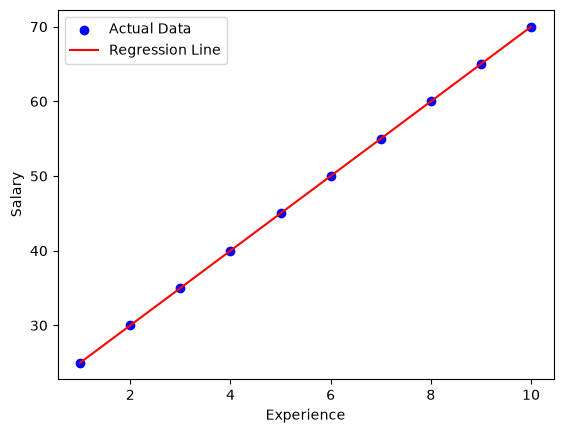

In [25]:
plt.scatter(X, y, color="blue", label="Actual Data")

plt.plot(
    X,
    model.predict(X),
    color="red",
    label="Regression Line"
)

plt.xlabel("Experience")
plt.ylabel("Salary")
plt.legend()
plt.show()

In [28]:
# Dataset
X = np.array([1, 2, 3], dtype=float)
y = np.array([3, 5, 7], dtype=float)

# Initial parameters
w = 0.0 # Theta1
b = 0.0 # Theta0

# Hyperparameters
learning_rate = 0.1
n_iter = 1000

n = len(X)

for i in range(n_iter):

    #Step 1: Predictions
    y_pred = w * X + b

    #Step 2: Calculate gradients
    dw = (2/n) * np.sum(X * (y_pred - y))
    db = (2/n) * np.sum(y_pred - y)

    # Step 3: Update parameters
    w = w - learning_rate * dw
    b = b - learning_rate * db

    # Step 4: Calculate Cost
    mse = np.mean((y_pred - y) ** 2)

    if i % 100 == 0:
        print(
            f"Epoch: {i}, "
            f"Weight: {w:.4f}, "
            f"Bias: {b:.4f}, "
            f"MSE: {mse:.4f}"
        )

print("\nFinal Weight:", w)
print("Final Bias:", b)

# Predict new value
new_x = 5
prediction = w * new_x + b

print("Prediction:", prediction)

Epoch: 0, Weight: 2.2667, Bias: 1.0000, MSE: 27.6667
Epoch: 100, Weight: 2.0038, Bias: 0.9914, MSE: 0.0000
Epoch: 200, Weight: 2.0003, Bias: 0.9992, MSE: 0.0000
Epoch: 300, Weight: 2.0000, Bias: 0.9999, MSE: 0.0000
Epoch: 400, Weight: 2.0000, Bias: 1.0000, MSE: 0.0000
Epoch: 500, Weight: 2.0000, Bias: 1.0000, MSE: 0.0000
Epoch: 600, Weight: 2.0000, Bias: 1.0000, MSE: 0.0000
Epoch: 700, Weight: 2.0000, Bias: 1.0000, MSE: 0.0000
Epoch: 800, Weight: 2.0000, Bias: 1.0000, MSE: 0.0000
Epoch: 900, Weight: 2.0000, Bias: 1.0000, MSE: 0.0000

Final Weight: 2.000000000001199
Final Bias: 0.9999999999972748
Prediction: 11.00000000000327
